# 02. 실험 결과 정리 (validation)

`scripts/run_experiment.py`가 만든 `results/metrics/e*.csv`를 읽어 요약 표·그림을 만들고, 기본 TrustRank의 오류와 seed 선정을 들여다본다.

- 모든 숫자는 **validation**이다. test는 `run_final_test.py`에서 마지막에 한 번만 본다.
- 실행 순서: 위에서부터 Run All. 1·2절은 CSV만, 3–5절은 `data/processed/`가 필요하다.
- 출력: 요약 표 → `results/metrics/summary_e*.md`, 분석 표 → `results/metrics/*.md`, 그림 → `results/figures/*.png`
- **탐색 결과 표시(\*)**: `domain_high_pr`(신뢰 도메인 후보 중 PageRank 상위)와 5절의 비교는 val 결과를 본 뒤 추가한 것이다. 미리 정한 비교(E1–E6의 나머지)와 구분해서 읽는다.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
METRICS = ROOT / "results" / "metrics"
FIGURES = ROOT / "results" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

E = {name: pd.read_csv(METRICS / f"{name}.csv") for name in ["e1", "e2", "e3", "e4", "e5", "e6"]
     if (METRICS / f"{name}.csv").exists()}
for df in E.values():                                # seed_strategy 열이 생기기 전에 만든 CSV는 random
    if "seed_strategy" not in df:
        df["seed_strategy"] = "random"
PREVALENCE = E["e1"]["prevalence"].iloc[0]          # val spam 비율 = PR-AUC의 무작위 기준선
print({k: len(v) for k, v in E.items()}, f"val spam 비율 {PREVALENCE:.4f}")

# 그림 공통 설정 (dataviz reference palette, light). 방법 색은 고정: 같은 방법은 모든 그림에서 같은 색.
COLOR = {"trustrank": "#257de0", "spam_mass": "#f47230", "hop": "#00b894"}
# E6는 같은 TrustRank를 seed 전략별로 비교하므로 방법 색과 겹치지 않는 슬롯을 쓴다.
STRATEGY_COLOR = {"random": "#6a4ce2", "high_pr": "#008a17", "svd": "#ee7fac"}
STRATEGY_LABEL = {"random": "Random", "high_pr": "Top PageRank", "svd": "SVD components",
                  "domain": "Trusted domain", "commercial": "co.uk only",
                  "domain_high_pr": "Trusted domain + top PR*"}
LABEL = {"random": "Random", "indegree": "In-degree", "pagerank": "PageRank",
         "pagerank_weighted": "PageRank (weighted)", "inverse_pagerank": "Inverse PageRank",
         "ppr": "PPR (ac.uk·gov.uk seeds)", "trustrank": "TrustRank", "spam_mass": "Spam mass",
         "hop": "Hop distance"}
INK, INK2, GRID = "#191919", "#666666", "#e6e6e6"
plt.rcParams.update({"font.size": 10, "axes.edgecolor": INK2, "axes.labelcolor": INK, "xtick.color": INK2,
                     "ytick.color": INK2, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
                     "legend.frameon": False, "savefig.dpi": 200, "savefig.bbox": "tight"})

{'e1': 50, 'e2': 50, 'e3': 120, 'e4': 40, 'e5': 40, 'e6': 120} val spam 비율 0.0558


## 1. 요약 표

조건(방법 × 설정)마다 random_seed 5번(같은 조건의 CSV 5줄)을 한 줄로 묶는다. 화면 표와 `summary_e*.md`는 같은 값이다(md에서는 PR-AUC ± sd, 95% CI로 합쳐 씀).

| 열 | 뜻 |
|---|---|
| PR-AUC | val PR-AUC(average precision)의 5번 평균. **주 지표**. 무작위 기준 ≈ val SPAM 비율 |
| sd | 5번 PR-AUC의 표준편차 = **seed 추첨에 따른 흔들림**. seed를 쓰지 않는 방법(PR, PPR, in-degree)과 난수를 안 쓰는 전략(high_pr, svd)은 0 |
| CI lo / CI hi (md: 95% CI) | 5번 각각의 PR-AUC bootstrap 95% CI 경계의 평균 = **val 표본에 따른 흔들림**. 방법 비교에는 쓰지 않는다 |
| ROC-AUC | SPAM 하나와 NONSPAM 하나를 뽑았을 때 SPAM의 risk가 더 높을 확률 (동점은 0.5). 무작위 0.5 |
| P@100 | risk 상위 100개 중 SPAM 비율. K번째 경계의 동점은 기대값으로 깬다 |
| tie | 가장 큰 동점 묶음이 val에서 차지하는 비율 (예: TR = 0 묶음 47/1200 = 0.039) |
| Δ vs ref | 기준 조건(표 위 설명의 "기준")과의 PR-AUC paired 차이의 5번 평균. 같은 random_seed끼리 짝짓고 같은 bootstrap 표본으로 계산. 기준 자신은 "기준"(0) |
| ↑ / ↓ | 5번 중 차이 CI가 0보다 확실히 위 / 아래였던 횟수. **차이 판단은 이 열로 한다** |
| runs | 묶인 줄 수 (보통 5) |

**PR-AUC 계산 방식 (동점 처리)**: sklearn의 average precision을 쓴다. 점수가 같은 host 묶음은 threshold 하나로 처리되어, 묶음 끝의 precision(묶음 안 기대 SPAM 수 ÷ host 수, *기댓값의 비율*)이 묶음 안 SPAM 모두에 쓰인다. 동점을 무작위로 깨고 SPAM마다 precision을 구해 평균내는 경우(*비율의 기댓값*)보다 낮게 나오므로, **동점이 많은 점수(Hop 약 51%, In-degree 약 11%)에 불리하다**. 그래서 동점 비율을 `tie` 열로 함께 보고한다. P@K는 K번째 경계의 동점을 기대값으로 깨므로 PR-AUC와 순위가 다를 수 있다.

**무작위 기준선**: val SPAM 비율 0.0558은 '모든 host가 동점'일 때의 PR-AUC다. 동점이 없는 무작위 점수의 기대 PR-AUC는 val 크기(1,200개, SPAM 67개)에서 약 0.061이다(시뮬레이션). E1의 Random(0.0645)이 0.0558보다 높은 이유다.

**95% CI 열**: val 표본에 따라 모든 방법이 같이 흔들리는 폭이라 방법끼리 크게 겹친다. 두 방법의 차이는 이 열이 아니라 같은 bootstrap 표본으로 계산한 paired 차이(↑ / ↓)로 판단한다.

**용어**: 표의 열 이름은 데이터셋 라벨 이름(NONSPAM / SPAM)을 쓰고, 설명에서는 '정상 / spam'도 같은 뜻으로 쓴다.

In [2]:
def summarize(df, keys):
    df = df[df["eval_subset"] == "val"]
    g = df.groupby(keys, sort=False)
    out = pd.DataFrame({
        "PR-AUC": g["pr_auc"].mean(), "sd": g["pr_auc"].std().fillna(0),
        "CI lo": g["pr_auc_lo"].mean(), "CI hi": g["pr_auc_hi"].mean(),
        "ROC-AUC": g["roc_auc"].mean(), "P@100": g["p@100"].mean(), "tie": g["tie_frac"].mean(),
        "Δ vs ref": g["diff_vs_ref"].mean(),
        "↑": g["diff_lo"].apply(lambda s: int((s > 0).sum())),
        "↓": g["diff_hi"].apply(lambda s: int((s < 0).sum())),
        "runs": g.size()})
    return out


def md_table(t):
    """pandas.to_markdown은 tabulate가 필요해서 직접 만든다."""
    fmt = lambda v: (f"{v:.0f}" if float(v).is_integer() else f"{v:.4f}") if isinstance(v, float) else str(v)
    head = "| " + " | ".join(map(str, t.columns)) + " |"
    rule = "|" + "|".join("---" for _ in t.columns) + "|"
    body = ["| " + " | ".join(fmt(v) for v in row) + " |" for row in t.itertuples(index=False)]
    return "\n".join([head, rule, *body])


def to_markdown(table, title, note):
    t = table.reset_index()
    t["PR-AUC"] = [f"{m:.4f} ± {s:.4f}" for m, s in zip(t["PR-AUC"], t["sd"])]
    t["95% CI"] = [f"{lo:.3f}–{hi:.3f}" for lo, hi in zip(t["CI lo"], t["CI hi"])]
    t["Δ vs ref"] = [("기준" if abs(d) < 1e-12 else f"{d:+.4f}") if pd.notna(d) else "" for d in t["Δ vs ref"]]
    if "method" in t:
        t["method"] = t["method"].map(LABEL).fillna(t["method"])
    t = t.drop(columns=["sd", "CI lo", "CI hi"])
    cols = [c for c in t.columns if c not in ("PR-AUC", "95% CI")]
    i = cols.index("ROC-AUC")
    cols = cols[:i] + ["PR-AUC", "95% CI"] + cols[i:]
    return f"### {title}\n\n{note}\n\n" + md_table(t[cols]) + "\n"


TABLES = {
    "e1": (["method"], "E1 방법 비교", "기준: 같은 random_seed의 기본 TrustRank (seed 100, noise 0, β 0.85)."),
    "e2": (["method", "seed_strategy"], "E2 seed 선정 전략", "seed 100개로 같게 두고 고르는 후보만 바꿈. 기준: random. "
           "domain_high_pr(*)는 val 결과(E2·E6)를 보고 추가한 탐색 전략으로, 사전에 정한 비교가 아니다."),
    "e3": (["method", "n_seeds"], "E3 seed 개수", "기준: seed 100개."),
    "e4": (["method", "contamination_rate"], "E4 seed noise", "기준: noise 0."),
    "e5": (["method", "beta"], "E5 β", "기준: β 0.85."),
    "e6": (["method", "n_seeds", "seed_strategy"], "E6 SVD seed",
           "seed 수마다 random·high_pr·svd 비교. svd는 인접 행렬 SVD 축마다 대표 host 하나 (축 수 = seed 수). 기준: 같은 seed 수의 random."),
}
for name, (keys, title, note) in TABLES.items():
    if name not in E:
        print(f"{name}.csv 없음 → 건너뜀")
        continue
    table = summarize(E[name], keys)
    if name == "e1":
        table = table.sort_values("PR-AUC", ascending=False)
    text = to_markdown(table, title, note + f" val spam 비율(무작위 PR-AUC) = {PREVALENCE:.4f}.")
    (METRICS / f"summary_{name}.md").write_text(text, encoding="utf-8")
    display(table.round(4))

,PR-AUC,sd,CI lo,CI hi,ROC-AUC,P@100,tie,Δ vs ref,↑,↓,runs
method,,,,,,,,,,,
ppr,0.0913,0.0000,0.0734,0.1269,0.6605,0.0860,0.0392,0.0073,5,0,5
indegree,0.0857,0.0000,0.0690,0.1176,0.6335,0.1058,0.1067,0.0011,0,0,5
spam_mass,0.0854,0.0034,0.0669,0.1221,0.6172,0.0910,0.0392,0.0014,2,0,5
trustrank,0.0841,0.0029,0.0654,0.1205,0.6080,0.0920,0.0392,0.0000,0,0,5
hop,0.0834,0.0055,0.0688,0.1132,0.6348,0.1095,0.5077,-0.0017,0,0,5
pagerank,0.0739,0.0000,0.0579,0.1059,0.5588,0.0800,0.0367,-0.0104,0,3,5
pagerank_weighted,0.0713,0.0000,0.0554,0.1024,0.5417,0.0900,0.0367,-0.0133,0,4,5
random,0.0645,0.0076,0.0494,0.1002,0.4988,0.0500,0.0008,-0.0196,0,1,5
inverse_pagerank,0.0642,0.0000,0.0531,0.0774,0.5295,0.0706,0.4133,-0.0228,0,3,5


,,PR-AUC,sd,CI lo,CI hi,ROC-AUC,P@100,tie,Δ vs ref,↑,↓,runs
method,seed_strategy,,,,,,,,,,,
trustrank,random,0.0841,0.0029,0.0654,0.1205,0.6080,0.0920,0.0392,0.0000,0,0,5
spam_mass,random,0.0854,0.0034,0.0669,0.1221,0.6172,0.0910,0.0392,0.0014,2,0,5
trustrank,domain,0.0899,0.0011,0.0717,0.1260,0.6493,0.0904,0.0392,0.0059,2,0,5
spam_mass,domain,0.0921,0.0011,0.0741,0.1289,0.6636,0.0894,0.0392,0.0081,5,0,5
trustrank,commercial,0.0819,0.0039,0.0632,0.1180,0.5881,0.0940,0.0392,-0.0023,0,2,5
spam_mass,commercial,0.0825,0.0046,0.0637,0.1188,0.5895,0.0930,0.0392,-0.0016,1,2,5
trustrank,high_pr,0.0914,0.0000,0.0711,0.1325,0.6307,0.1110,0.0392,0.0077,4,0,5
spam_mass,high_pr,0.0932,0.0000,0.0728,0.1346,0.6383,0.1100,0.0392,0.0095,5,0,5
trustrank,domain_high_pr,0.0926,0.0000,0.0732,0.1324,0.6508,0.1090,0.0392,0.0087,5,0,5


,,PR-AUC,sd,CI lo,CI hi,ROC-AUC,P@100,tie,Δ vs ref,↑,↓,runs
method,n_seeds,,,,,,,,,,,
trustrank,10,0.0856,0.0029,0.0673,0.1221,0.6226,0.0860,0.0392,0.0015,0,1,5
spam_mass,10,0.0872,0.0033,0.0690,0.1240,0.6307,0.0868,0.0392,0.0031,2,0,5
hop,10,0.0808,0.0039,0.0659,0.1112,0.6206,0.1064,0.4978,-0.0044,0,1,5
trustrank,20,0.0851,0.0021,0.0668,0.1216,0.6167,0.0864,0.0392,0.0010,0,1,5
spam_mass,20,0.0865,0.0024,0.0681,0.1230,0.6245,0.0854,0.0392,0.0024,1,0,5
hop,20,0.0793,0.0048,0.0643,0.1087,0.6126,0.1048,0.5217,-0.0060,0,1,5
trustrank,50,0.0834,0.0026,0.0651,0.1195,0.6067,0.0918,0.0392,-0.0007,0,1,5
spam_mass,50,0.0846,0.0030,0.0662,0.1208,0.6144,0.0908,0.0392,0.0005,1,0,5
hop,50,0.0852,0.0065,0.0699,0.1152,0.6424,0.1134,0.5368,0.0000,0,0,5


,,PR-AUC,sd,CI lo,CI hi,ROC-AUC,P@100,tie,Δ vs ref,↑,↓,runs
method,contamination_rate,,,,,,,,,,,
trustrank,0.00,0.0841,0.0029,0.0654,0.1205,0.6080,0.0920,0.0392,0.0000,0,0,5
spam_mass,0.00,0.0854,0.0034,0.0669,0.1221,0.6172,0.0910,0.0392,0.0014,2,0,5
trustrank,0.05,0.0834,0.0030,0.0648,0.1196,0.6044,0.0908,0.0392,-0.0007,0,1,5
spam_mass,0.05,0.0845,0.0036,0.0660,0.1211,0.6122,0.0898,0.0392,0.0004,0,0,5
trustrank,0.10,0.0820,0.0023,0.0637,0.1178,0.5979,0.0892,0.0392,-0.0021,0,2,5
spam_mass,0.10,0.0831,0.0029,0.0648,0.1193,0.6051,0.0882,0.0392,-0.0010,0,1,5
trustrank,0.20,0.0819,0.0042,0.0633,0.1175,0.5921,0.0908,0.0392,-0.0023,0,3,5
spam_mass,0.20,0.0828,0.0050,0.0642,0.1190,0.5987,0.0900,0.0392,-0.0013,0,1,5


,,PR-AUC,sd,CI lo,CI hi,ROC-AUC,P@100,tie,Δ vs ref,↑,↓,runs
method,beta,,,,,,,,,,,
trustrank,0.70,0.0845,0.0029,0.0660,0.1211,0.6099,0.0938,0.0392,0.0004,0,0,5
spam_mass,0.70,0.0853,0.0031,0.0667,0.1218,0.6158,0.0932,0.0392,0.0012,0,0,5
trustrank,0.80,0.0843,0.0029,0.0656,0.1208,0.6089,0.0930,0.0392,0.0002,0,0,5
spam_mass,0.80,0.0854,0.0032,0.0669,0.1222,0.6166,0.0940,0.0392,0.0013,1,0,5
trustrank,0.85,0.0841,0.0029,0.0654,0.1205,0.6080,0.0920,0.0392,0.0000,0,0,5
spam_mass,0.85,0.0854,0.0034,0.0669,0.1221,0.6172,0.0910,0.0392,0.0014,2,0,5
trustrank,0.90,0.0839,0.0029,0.0652,0.1203,0.6074,0.0920,0.0392,-0.0002,0,0,5
spam_mass,0.90,0.0855,0.0036,0.0671,0.1220,0.6184,0.0906,0.0392,0.0015,2,0,5


,,,PR-AUC,sd,CI lo,CI hi,ROC-AUC,P@100,tie,Δ vs ref,↑,↓,runs
method,n_seeds,seed_strategy,,,,,,,,,,,
trustrank,10,random,0.0856,0.0029,0.0673,0.1221,0.6226,0.0860,0.0392,0.0000,0,0,5
spam_mass,10,random,0.0872,0.0033,0.0690,0.1240,0.6307,0.0868,0.0392,0.0017,2,0,5
trustrank,10,high_pr,0.0897,0.0000,0.0721,0.1249,0.6548,0.0850,0.0392,0.0042,3,0,5
spam_mass,10,high_pr,0.0920,0.0000,0.0744,0.1284,0.6704,0.0840,0.0392,0.0065,4,0,5
trustrank,10,svd,0.0901,0.0000,0.0722,0.1264,0.6540,0.0840,0.0392,0.0047,3,0,5
spam_mass,10,svd,0.0920,0.0000,0.0743,0.1279,0.6666,0.0830,0.0392,0.0066,4,0,5
trustrank,20,random,0.0851,0.0021,0.0668,0.1216,0.6167,0.0864,0.0392,0.0000,0,0,5
spam_mass,20,random,0.0865,0.0024,0.0681,0.1230,0.6245,0.0854,0.0392,0.0014,2,0,5
trustrank,20,high_pr,0.0908,0.0000,0.0720,0.1290,0.6463,0.0970,0.0392,0.0059,4,0,5


### 1-2. PPR: seed host를 뺀 평가

PPR은 ac.uk·gov.uk host를 seed로 쓴다. seed host 자체는 risk가 낮게 나오기 쉬우므로, seed host를 뺀 val(`val_no_seed`)로도 평가해 점수가 seed 덕분만은 아닌지 확인한다.

| 열 | 뜻 |
|---|---|
| eval_subset | `val`: val 전체 / `val_no_seed`: PPR seed(ac.uk·gov.uk host)를 뺀 val |
| n_eval | 평가한 host 수 |
| n_pos | 그중 SPAM 수 |
| pr_auc, roc_auc | 5번 평균 (PPR은 seed가 고정이라 5번 모두 같다) |

In [3]:
ppr = E["e1"][E["e1"]["method"] == "ppr"].groupby("eval_subset")[["n_eval", "n_pos", "pr_auc", "roc_auc"]].mean()
ppr.round(4)

,n_eval,n_pos,pr_auc,roc_auc
eval_subset,,,,
val,1200.0,67.0,0.0913,0.6605
val_no_seed,1143.0,67.0,0.0913,0.6425


## 2. 그림

- 같은 방법은 모든 그림에서 같은 색이다 (TrustRank 파랑, Spam mass 주황, Hop 청록).
- E1 막대의 오차 막대는 방법별 95% bootstrap CI(5번 평균), 회색 점선은 val SPAM 비율이다. 오차 막대가 겹친다고 차이가 없다는 뜻은 아니다 (1절 설명 참고).
- E2–E6는 두 칸이다. 왼쪽은 조건별 PR-AUC(5번 평균), 오른쪽은 기준 조건과의 **paired 차이**다.
  - 오른쪽 오차 막대는 **5번 실행 각각의 95% CI 경계를 평균낸 대표 폭**이다. 5번 평균 차이의 엄밀한 CI가 아니며 그보다 넓다.
  - 차이가 확실한지는 실행마다 CI가 0을 벗어났는지 센 횟수(1절 표의 ↑ / ↓)로 판단한다.
- E3의 x축(seed 10 ~ 전체)은 **등간격 범주형**이다. 실제 간격은 로그에 가까우므로 기울기를 'seed 1개당 효과'로 읽지 않는다.

### 2-1. E1 방법 비교

방법별 PR-AUC를 높은 순으로 세운 가로 막대. 오차 막대는 95% bootstrap CI(5번 평균), 회색 점선은 무작위 기준선이다.

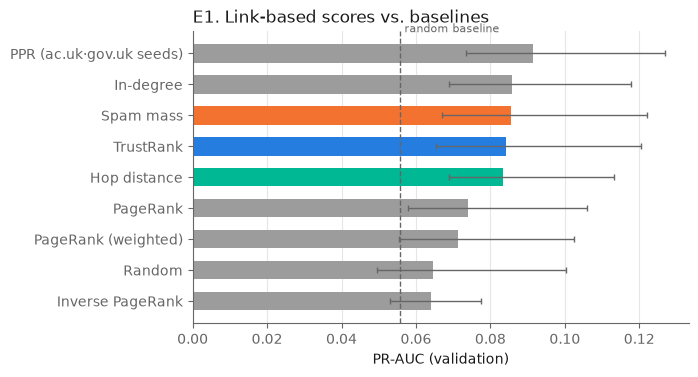

In [4]:
def ci_err(t):
    return np.vstack([t["PR-AUC"] - t["CI lo"], t["CI hi"] - t["PR-AUC"]])


# E1: 방법별 PR-AUC (가로 막대, 높은 순)
t1 = summarize(E["e1"], ["method"]).sort_values("PR-AUC")
fig, ax = plt.subplots(figsize=(6.4, 3.8))
colors = [COLOR.get(m, "#9c9c9c") for m in t1.index]
y = np.arange(len(t1))
ax.barh(y, t1["PR-AUC"], height=0.6, color=colors)
ax.errorbar(t1["PR-AUC"], y, xerr=ci_err(t1), fmt="none", ecolor=INK2, elinewidth=1, capsize=2)
ax.axvline(PREVALENCE, color=INK2, linestyle="--", linewidth=1)
ax.text(PREVALENCE, len(t1) - 0.4, " random baseline", color=INK2, fontsize=8, va="bottom")
ax.set_yticks(y, [LABEL[m] for m in t1.index])
ax.set_xlabel("PR-AUC (validation)")
ax.set_title("E1. Link-based scores vs. baselines", loc="left", color=INK)
ax.grid(axis="y", visible=False)
fig.savefig(FIGURES / "e1_methods.png")
plt.show()

### 2-2. 그림 함수

- `sweep`: E2–E5용. 왼쪽은 조건별 PR-AUC, 오른쪽은 기준 조건과의 paired 차이와 95% CI.
- `strategy_sweep`: E6용. 같은 TrustRank를 seed 전략별로, seed 수에 따라 비교한다.
- `label_ends`: 선 끝 직접 라벨이 겹치지 않게 위아래로 민다.

In [5]:
def label_ends(ax, x_end, ends, min_gap):
    """선 끝 직접 라벨이 겹치지 않게 위아래로 조금씩 민다."""
    items = sorted(ends.items(), key=lambda kv: kv[1])
    placed = []
    for method, yv in items:
        y_pos = max(yv, placed[-1] + min_gap) if placed else yv
        placed.append(y_pos)
        ax.annotate(LABEL[method], (x_end, yv), xytext=(x_end + 0.15, y_pos), textcoords="data",
                    color=INK, fontsize=8, va="center")


def sweep(name, key, xlabel, title, fname, xticks=None, categorical=False):
    """왼쪽: 조건별 PR-AUC (5번 평균). 오른쪽: 기준 조건과의 paired 차이와 95% CI."""
    t = summarize(E[name], ["method", key]).reset_index()
    order = list(dict.fromkeys(E[name][key]))           # 설정 파일 순서 그대로
    x = np.arange(len(order))
    ticks = xticks or [str(v) for v in order]
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.6), gridspec_kw={"wspace": 0.45})
    methods = list(dict.fromkeys(t["method"]))
    offsets = np.linspace(-0.12, 0.12, len(methods))

    ends = {}
    for method in methods:
        g = t[t["method"] == method].set_index(key).loc[order]
        ax1.plot(x + (offsets[methods.index(method)] if categorical else 0), g["PR-AUC"], color=COLOR[method],
                 linewidth=0 if categorical else 2, marker="o", markersize=6, label=LABEL[method])
        ends[method] = g["PR-AUC"].iloc[-1]
    ax1.axhline(PREVALENCE, color=INK2, linestyle="--", linewidth=1)
    ax1.text(x[0], PREVALENCE, "random baseline", color=INK2, fontsize=8, va="bottom")
    span = ax1.get_ylim()[1] - ax1.get_ylim()[0]
    if not categorical:                                 # 범주형(E2)은 점이 흩어져 있어 범례만 둔다
        label_ends(ax1, x[-1], ends, min_gap=span * 0.06)
    ax1.set_xlim(-0.3, len(order) - 1 + 1.4)
    ax1.set_xticks(x, ticks, fontsize=8 if categorical else None)
    ax1.set_xlabel(xlabel)
    ax1.set_ylabel("PR-AUC (validation)")
    ax1.set_title(f"{title}: PR-AUC", loc="left", color=INK)

    for off, method in zip(offsets, methods):
        g = t[t["method"] == method].set_index(key).loc[order]
        lo = (E[name].query("eval_subset == 'val' and method == @method").groupby(key)["diff_lo"].mean().loc[order])
        hi = (E[name].query("eval_subset == 'val' and method == @method").groupby(key)["diff_hi"].mean().loc[order])
        d = g["Δ vs ref"]
        ax2.errorbar(x + off, d, yerr=np.vstack([d - lo, hi - d]), color=COLOR[method], fmt="o", markersize=5,
                     elinewidth=1.5, capsize=0, label=LABEL[method])
    ax2.axhline(0, color=INK2, linewidth=1)
    ref_method, *ref_params = E[name]["ref"].dropna().iloc[0].split(",")
    ref = ", ".join([LABEL[ref_method], *ref_params])
    ax2.set_xticks(x, ticks, fontsize=8 if categorical else None)
    ax2.set_xlabel(xlabel)
    ax2.set_ylabel("Δ PR-AUC vs reference (paired)")
    ax2.set_title(f"Paired difference vs {ref}", loc="left", color=INK, fontsize=10)
    handles, labels = ax2.get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", ncol=len(methods), fontsize=8, bbox_to_anchor=(0.5, 1.06))
    fig.savefig(FIGURES / fname)
    plt.show()



def strategy_sweep(name, fname, method="trustrank"):
    """E6: 같은 방법(TrustRank)을 seed 전략별로, seed 수에 따라 비교한다."""
    df = E[name][(E[name]["eval_subset"] == "val") & (E[name]["method"] == method)]
    order = list(dict.fromkeys(df["n_seeds"]))
    x = np.arange(len(order))
    strategies = list(dict.fromkeys(df["seed_strategy"]))
    offsets = np.linspace(-0.12, 0.12, len(strategies))
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.6), gridspec_kw={"wspace": 0.45})
    ends = {}
    for off, st in zip(offsets, strategies):
        g = df[df["seed_strategy"] == st].groupby("n_seeds").agg(
            pr=("pr_auc", "mean"), d=("diff_vs_ref", "mean"), lo=("diff_lo", "mean"), hi=("diff_hi", "mean")).loc[order]
        ax1.plot(x, g["pr"], color=STRATEGY_COLOR[st], linewidth=2, marker="o", markersize=5, label=STRATEGY_LABEL[st])
        ends[st] = g["pr"].iloc[-1]
        ax2.errorbar(x + off, g["d"], yerr=np.vstack([g["d"] - g["lo"], g["hi"] - g["d"]]), color=STRATEGY_COLOR[st],
                     fmt="o", markersize=5, elinewidth=1.5, capsize=0, label=STRATEGY_LABEL[st])
    ax1.axhline(PREVALENCE, color=INK2, linestyle="--", linewidth=1)
    ax1.text(x[0], PREVALENCE, "random baseline", color=INK2, fontsize=8, va="bottom")
    span = ax1.get_ylim()[1] - ax1.get_ylim()[0]
    placed = []
    for st, yv in sorted(ends.items(), key=lambda kv: kv[1]):      # 라벨이 겹치지 않게 위로 민다
        y_pos = max(yv, placed[-1] + span * 0.06) if placed else yv
        placed.append(y_pos)
        ax1.annotate(STRATEGY_LABEL[st], (x[-1], yv), xytext=(x[-1] + 0.15, y_pos), textcoords="data",
                     color=INK, fontsize=8, va="center")
    ax1.set_xlim(-0.3, len(order) - 1 + 1.4)
    for ax in (ax1, ax2):
        ax.set_xticks(x, [str(v) for v in order])
        ax.set_xlabel("Number of seeds (= SVD components for SVD)")
    ax1.set_ylabel(f"{LABEL[method]} PR-AUC (validation)")
    ax1.set_title("E6. SVD seeds: PR-AUC", loc="left", color=INK)
    ax2.axhline(0, color=INK2, linewidth=1)
    ax2.set_ylabel("Δ PR-AUC vs random (paired)")
    ax2.set_title("Paired difference vs random seeds (same count)", loc="left", color=INK, fontsize=10)
    handles, labels = ax2.get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", ncol=len(strategies), fontsize=8, bbox_to_anchor=(0.5, 1.06))
    fig.savefig(FIGURES / fname)
    plt.show()

### 2-3. E2 seed 선정 전략

seed 100개로 같게 두고, 어느 후보에서 고르는지만 바꾼다 (random / trusted domain / co.uk only / top PageRank / trusted domain + top PageRank\*). \* 표시는 탐색 결과다.

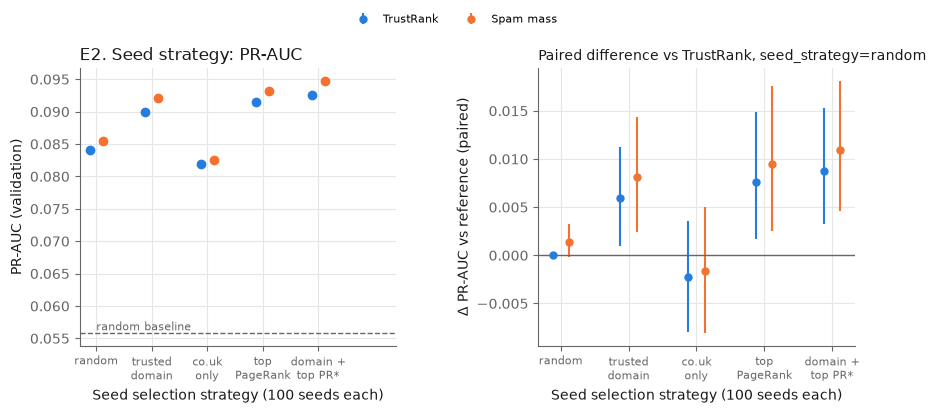

In [6]:
if "e2" in E:
    sweep("e2", "seed_strategy", "Seed selection strategy (100 seeds each)", "E2. Seed strategy", "e2_seed_strategy.png",
          xticks=["random", "trusted\ndomain", "co.uk\nonly", "top\nPageRank", "domain +\ntop PR*"], categorical=True)

### 2-4. E3–E5 seed 개수 · seed noise · β

기본 TrustRank에서 설정 하나씩만 바꾼다. 기준은 각각 seed 100개, noise 0, β 0.85.

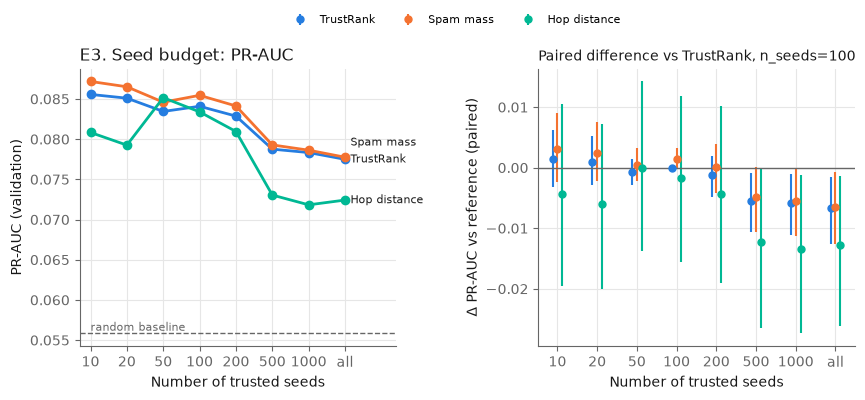

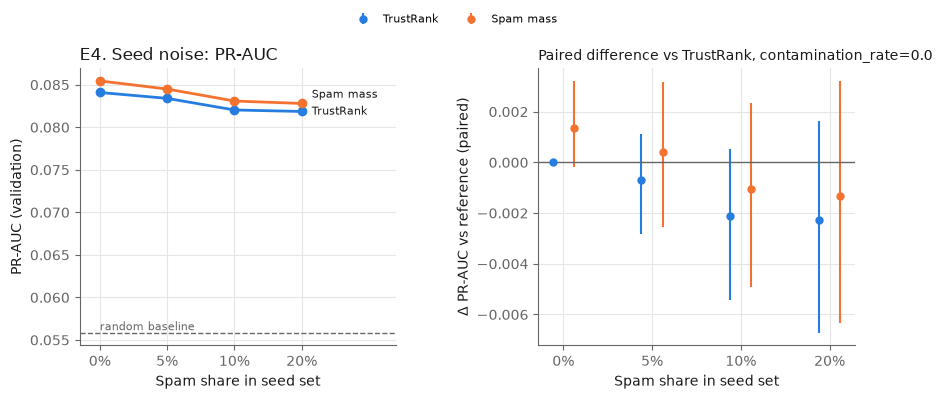

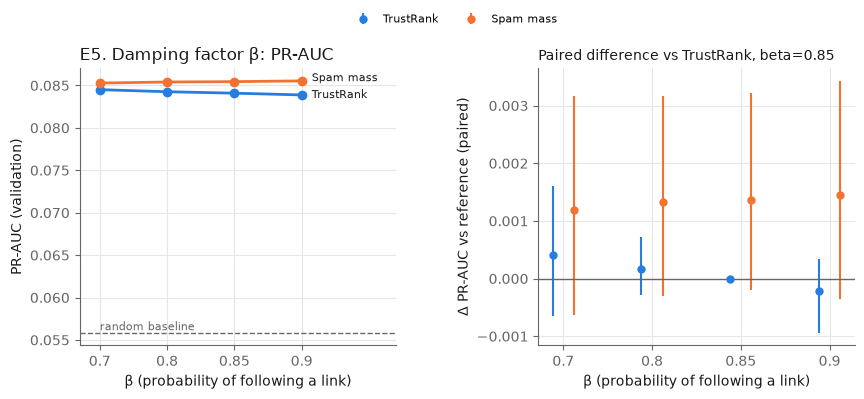

In [7]:
sweep("e3", "n_seeds", "Number of trusted seeds", "E3. Seed budget", "e3_seed_budget.png")
sweep("e4", "contamination_rate", "Spam share in seed set", "E4. Seed noise", "e4_seed_noise.png",
      xticks=["0%", "5%", "10%", "20%"])
sweep("e5", "beta", "β (probability of following a link)", "E5. Damping factor β", "e5_beta.png")

### 2-5. E6 SVD seed

seed 수(= SVD 축 수)마다 random · top PageRank · SVD를 비교한다. 오른쪽은 같은 seed 수의 random과의 paired 차이.

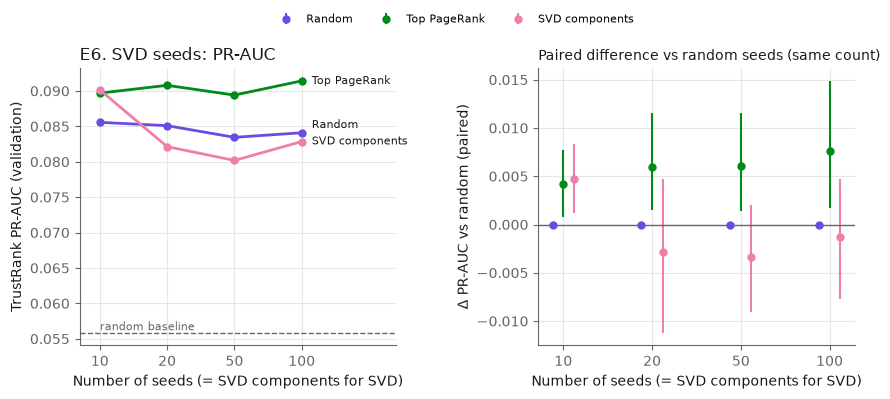

In [8]:
if "e6" in E:
    strategy_sweep("e6", "e6_svd_seeds.png")

## 3. 오류 분석 (기본 TrustRank, validation)

기본 설정(Random seed 100개, random_seed 0, noise 0, β 0.85)의 TrustRank를 다시 계산해 val host를 들여다본다.

| 절 | 내용 |
|---|---|
| 3-1 | TR = 0 묶음: seed에서 닿지 않아 risk 맨 위에 동점으로 모이는 host |
| 3-2 | 틀린 host 예시: 오탐(risk 높은 NONSPAM) · 놓친 SPAM(risk 낮은 SPAM) |
| 3-3 | 틀린 host 집계: 오탐 · 놓친 SPAM의 연결 특징 |
| 3-4 | 도메인별 경향 |
| 3-5 | 기본 seed의 도메인 구성 |
| 3-6 | seed 전략별 구성과 도달 범위 |
| 3-7 | seed 전략별 도메인 위험도 · 놓친 SPAM |

In [9]:
from scipy.stats import spearmanr

from src.common.schema import NONSPAM
from src.config import load_config
from src.data import load_dataset
from src.graph import build_transition, domain_of
from src.metrics import eval_arrays, pr_auc
from src.rank import pagerank
from src.seeds import select_trusted_seeds
from src.trust import hop_distance, trustrank

cfg = load_config()
ds = load_dataset(cfg.path("processed_dir"))
A = ds.graph.adjacency
M = build_transition(A)
rank = {k: cfg.require("rank", k) for k in ("beta", "tol", "max_iter", "dangling")}

seeds = select_trusted_seeds(ds, n_seeds=100, random_seed=0, contamination_rate=0.0)
tr = trustrank(M, seeds, **rank)
pr = pagerank(M, **rank)
hop = hop_distance(A, seeds)
in_deg = np.asarray((A > 0).sum(axis=0)).ravel()
out_deg = np.asarray((A > 0).sum(axis=1)).ravel()

idx, y = eval_arrays(ds, "val")
val = pd.DataFrame({"host": [ds.graph.hostnames[i] for i in idx], "spam": y, "tr": tr[idx],
                    "risk": -tr[idx], "pr": pr[idx], "hop": hop[idx],
                    "in_deg": in_deg[idx], "out_deg": out_deg[idx]})
val["domain"] = [domain_of(h) for h in val["host"]]
print(f"기본 TR val PR-AUC = {pr_auc(val['risk'], val['spam']):.4f} (e1.csv random_seed 0과 같아야 함)")

기본 TR val PR-AUC = 0.0850 (e1.csv random_seed 0과 같아야 함)


### 3-1. TR = 0 묶음

seed에서 링크를 따라 닿지 않는 host는 TR이 정확히 0이라 risk 맨 위에 동점으로 모인다. 이 묶음의 SPAM 비율과 in-degree 0 비율을 닿은 host와 비교한다.

| 열 | 뜻 |
|---|---|
| host 수 | 행에 해당하는 val host 수 |
| 비율 | val 1,200개 중 그 행의 비율 |
| SPAM 비율 | 그 행 host 중 SPAM 비율 (val 전체는 5.6%) |
| in-degree 0 비율 | 그 행 host 중 들어오는 링크가 하나도 없는 host 비율 |

in-degree 0 ⊂ TR = 0이다. 들어오는 링크가 없으면 어떤 seed로도 닿지 않는다. TR = 0인데 in-degree가 1 이상인 host는 링크를 준 host 자체가 seed에서 닿지 않는 경우다.

In [10]:
zero = val["tr"] == 0
summary = pd.DataFrame({
    "host 수": [zero.sum(), (~zero).sum()],
    "비율": [zero.mean(), (~zero).mean()],
    "SPAM 비율": [val.loc[zero, "spam"].mean(), val.loc[~zero, "spam"].mean()],
    "in-degree 0 비율": [(val.loc[zero, "in_deg"] == 0).mean(), (val.loc[~zero, "in_deg"] == 0).mean()],
}, index=["TR = 0 (seed에서 닿지 않음)", "TR > 0"])
summary.round(4)

,host 수,비율,SPAM 비율,in-degree 0 비율
TR = 0 (seed에서 닿지 않음),47,0.0392,0.1489,0.9362
TR > 0,1153,0.9608,0.0520,0.0000


### 3-2. 틀린 host 예시

TR > 0(닿은 host)만 risk 순으로 세운 뒤,
- **오탐**: risk가 가장 높은 NONSPAM 10개
- **놓친 SPAM**: TR이 가장 높은(가장 안전해 보이는) SPAM 10개

| 열 | 뜻 |
|---|---|
| host | hostname |
| domain | .uk 2단계 도메인 (`domain_of`, 목록 밖은 other) |
| in_deg / out_deg | 링크를 **받는(in) / 거는(out)** 상대 host 수. 같은 상대와의 링크가 여러 개여도 1로 센다 |
| hop | 가장 가까운 seed에서 out-link를 따라 몇 번 만에 닿는지 |
| tr | TrustRank 값 (합 1로 정규화, 클수록 안전) |

In [11]:
reach = val[~zero].sort_values("risk", ascending=False)
cols = ["host", "domain", "in_deg", "out_deg", "hop", "tr"]
print("risk가 높은데 정상 (TR > 0 중 상위 10)")
display(reach[reach["spam"] == 0].head(10)[cols])
print("risk가 낮은데 spam (TR 가장 높은 spam 10)")
display(reach[reach["spam"] == 1].tail(10)[cols])

risk가 높은데 정상 (TR > 0 중 상위 10)


,host,domain,in_deg,out_deg,hop,tr
62,totnesearlymusic.org.uk,org.uk,1,0,5.0,1.118698e-13
103,www.afewgoodmen.org.uk,org.uk,1,0,4.0,2.105784e-12
133,www.angusmeatswales.co.uk,co.uk,1,0,4.0,2.105784e-12
790,www.mortgagesforchristians.co.uk,co.uk,1,2,4.0,2.105784e-12
1015,www.somewherelse.co.uk,co.uk,1,3,4.0,2.105784e-12
647,www.jane-lane.walsall.sch.uk,sch.uk,1,0,4.0,2.105784e-12
1120,www.tlc-ltd.co.uk,co.uk,1,0,4.0,2.105784e-12
791,www.morwethcourt.co.uk,co.uk,1,0,4.0,7.739876e-12
324,www.comfyquilts.co.uk,co.uk,1,0,3.0,4.263493e-11
574,www.handweaving.co.uk,co.uk,2,0,3.0,4.474072e-11


risk가 낮은데 spam (TR 가장 높은 spam 10)


,host,domain,in_deg,out_deg,hop,tr
1100,www.thefurnituredirectory.co.uk,co.uk,19,11,3.0,9.693765e-07
590,www.hertfordshiremobilediscos.co.uk,co.uk,7,6,3.0,1.450960e-06
489,www.financelink.co.uk,co.uk,30,5,2.0,1.918215e-06
349,www.creditcards247.co.uk,co.uk,8,0,3.0,2.374928e-06
622,www.i-biker.co.uk,co.uk,4,2,2.0,2.447558e-06
427,www.e-crm.co.uk,co.uk,17,40,3.0,3.305768e-06
1140,www.uk-shoponline.co.uk,co.uk,44,3,3.0,7.429476e-06
1117,www.timsibley.co.uk,co.uk,11,6,2.0,7.572584e-06
1044,www.statistics.006.free-counter.co.uk,co.uk,2,1,3.0,9.256035e-06
356,www.cruisemaestro.co.uk,co.uk,4,4,2.0,1.506370e-05


### 3-3. 틀린 host 집계

3-2의 예시를 묶음 단위로 센다. val을 risk 순으로 세웠을 때의 위치로 정의한다.

| 묶음 | 정의 |
|---|---|
| 오탐 | 닿은 host(TR > 0) 중 risk 상위 10%에 있는 NONSPAM |
| NONSPAM (나머지) | 그 밖의 닿은 NONSPAM (비교 기준) |
| 잡힌 SPAM | 닿은 host 중 risk 상위 10%에 있는 SPAM |
| 놓친 SPAM | val 전체 risk 순위가 안전한 쪽 절반에 있는 SPAM |

- TR = 0 묶음은 동점이라 상위 10%를 자를 수 없어서 오탐 · 잡힌 SPAM 집계에서 뺀다 (3-1에서 따로 봄).
- 오탐은 "가장 강하게 의심한 곳의 NONSPAM", 놓친 SPAM은 "안전하다고 본 SPAM"을 보려는 것이라 **기준이 다르다**. 두 묶음의 host 수를 서로 비교하지 말고, 각 묶음의 특징을 NONSPAM (나머지)와 비교한다.

| 열 | 뜻 |
|---|---|
| host 수 | 묶음에 속한 val host 수 |
| in-deg 중앙값 / out-deg 중앙값 | 묶음 host의 in-degree / out-degree 중앙값 |
| hop 중앙값 | seed에서의 hop 거리 중앙값 |
| PR 순위 중앙값 | 전체 114,529개 host 중 PageRank 순위의 중앙값 (1 = 가장 높음, 클수록 인기 없음) |
| co.uk 비율 / ac.uk·gov.uk 비율 | 묶음 host 중 해당 도메인 비율 |

In [12]:
n_reach = len(reach)
top10 = reach.head(int(np.ceil(n_reach * 0.10)))             # reach: 3-2에서 risk 높은 순으로 정렬한 닿은 host
val["risk_pct"] = val["risk"].rank(pct=True)                   # 1에 가까울수록 위험
pr_rank_all = (-pr).argsort().argsort() + 1                    # 1 = PageRank 1위
val["pr_rank"] = pr_rank_all[idx]

groups = {
    "오탐": val.loc[top10.index][lambda d: d["spam"] == 0],
    "NONSPAM (나머지)": val.loc[reach.index.difference(top10.index)][lambda d: d["spam"] == 0],
    "잡힌 SPAM": val.loc[top10.index][lambda d: d["spam"] == 1],
    "놓친 SPAM": val[(val["spam"] == 1) & (val["risk_pct"] < 0.5)],
}
error_profile = pd.DataFrame({
    name: {"host 수": len(g), "in-deg 중앙값": g["in_deg"].median(), "out-deg 중앙값": g["out_deg"].median(),
           "hop 중앙값": g["hop"].median(), "PR 순위 중앙값": g["pr_rank"].median(),
           "co.uk 비율": (g["domain"] == "co.uk").mean(),
           "ac.uk·gov.uk 비율": g["domain"].isin(["ac.uk", "gov.uk"]).mean()}
    for name, g in groups.items()}).T
(METRICS / "error_profile.md").write_text(
    "### 기본 TR 오탐·놓친 SPAM 집계 (random seed 100, random_seed 0, val)\n\n"
    + md_table(error_profile.round(3).reset_index().rename(columns={"index": "묶음"})) + "\n", encoding="utf-8")
error_profile.round(3)

,host 수,in-deg 중앙값,out-deg 중앙값,hop 중앙값,PR 순위 중앙값,co.uk 비율,ac.uk·gov.uk 비율
오탐,109.0,3.0,0.0,3.0,104282.0,0.881,0.009
NONSPAM (나머지),984.0,6.0,1.0,3.0,52515.0,0.756,0.057
잡힌 SPAM,7.0,3.0,0.0,3.0,103886.0,0.857,0.000
놓친 SPAM,24.0,6.5,2.0,3.0,32172.0,1.000,0.000


### 3-4. 도메인별 경향

도메인별 SPAM 비율과 평균 risk 순위(0–1, 1에 가까울수록 위험). 어떤 도메인에서 TR이 헷갈리는지 본다.

| 열 | 뜻 |
|---|---|
| host 수 | 그 도메인의 val host 수 (host 수 순으로 상위 10개 도메인) |
| SPAM 비율 | 그 도메인 host 중 SPAM 비율 |
| 평균 risk 순위 | val 전체를 risk 순으로 0–1 백분위로 바꾼 값의 평균. 1에 가까울수록 위험하게 평가됨, 무작위면 약 0.5 |

In [13]:
val["risk_rank_pct"] = val["risk"].rank(pct=True)
by_dom = val.groupby("domain").agg(**{"host 수": ("spam", "size"), "SPAM 비율": ("spam", "mean"),
                                      "평균 risk 순위": ("risk_rank_pct", "mean")}).sort_values("host 수", ascending=False)
by_dom.head(10).round(3)

,host 수,SPAM 비율,평균 risk 순위
domain,,,
co.uk,941,0.068,0.539
org.uk,176,0.017,0.350
ac.uk,40,0.000,0.313
gov.uk,17,0.000,0.272
sch.uk,13,0.000,0.731
nhs.uk,6,0.000,0.346
me.uk,4,0.000,0.420
ltd.uk,2,0.000,0.765
net.uk,1,0.000,0.128


### 3-5. 기본 seed의 도메인 구성

기본 TR seed 100개가 어느 도메인에서 왔는지 **seed 모집단(train NONSPAM 2,643개)**의 구성과 비교한다. 무작위로 뽑았으므로 모집단 비율 × 100 근처가 기대된다. val NONSPAM 비율은 참고 열이다 (분할은 라벨로만 층화했고 도메인은 기준에 없지만, 표본이 커서 train과 val의 구성이 비슷하다).

| 열 | 뜻 |
|---|---|
| seed 수 | 기본 seed 100개 중 그 도메인 host 수 |
| 기대 seed 수 | 모집단 비율 × 100. 무작위 추첨이면 seed 수가 이 근처에 온다 |
| train NONSPAM 비율 (모집단) | seed 후보(train NONSPAM 2,643개) 중 그 도메인 비율 |
| 참고: val NONSPAM 비율 | val NONSPAM 중 그 도메인 비율 |

In [14]:
pool_all = ds.train_idx[ds.labels[ds.train_idx] == NONSPAM]          # 기본 seed의 모집단
seed_dom = pd.Series([domain_of(ds.graph.hostnames[i]) for i in seeds]).value_counts()
pool_dom = pd.Series([domain_of(ds.graph.hostnames[i]) for i in pool_all]).value_counts(normalize=True)
val_ns_dom = val.loc[val["spam"] == 0, "domain"].value_counts(normalize=True)
pd.DataFrame({"seed 수": seed_dom,
              "기대 seed 수 (모집단 비율 × 100)": 100 * pool_dom.reindex(seed_dom.index),
              "train NONSPAM 비율 (모집단)": pool_dom.reindex(seed_dom.index),
              "참고: val NONSPAM 비율": val_ns_dom.reindex(seed_dom.index)}).round(3)

,seed 수,기대 seed 수 (모집단 비율 × 100),train NONSPAM 비율 (모집단),참고: val NONSPAM 비율
co.uk,77,77.147,0.771,0.774
org.uk,15,13.394,0.134,0.153
ac.uk,3,4.729,0.047,0.035
gov.uk,3,2.194,0.022,0.015
sch.uk,2,1.665,0.017,0.011


### 3-6. seed 전략별 구성과 도달 범위

E2의 전략이 고른 seed(random_seed 0, seed 100개)를 비교한다. `domain_high_pr`\*는 탐색 결과다.

| 열 | 뜻 |
|---|---|
| 후보 수 | 전략이 seed를 고르는 후보 수 (모두 train NONSPAM 안에서) |
| 비상업 비율 | seed 중 co.uk가 아닌 비율 |
| in-deg 중앙값 / out-deg 중앙값 | seed 100개의 in-degree / out-degree 중앙값 |
| PR 순위 중앙값 | seed 100개의 PageRank 순위 중앙값 (전체 114,529개 중, 1 = 가장 높음) |
| NONSPAM / SPAM ≤2 hop | val NONSPAM(SPAM) 중 seed에서 링크 2번 이내로 닿는 비율 |
| TR NONSPAM÷SPAM 평균 | val NONSPAM 평균 TR ÷ val SPAM 평균 TR. TR은 seed 근처에 몰려 있어 **seed 바로 옆 몇몇 host의 큰 값에 끌려간다** |
| TR NONSPAM÷SPAM 중앙값 | 보통의 NONSPAM과 보통의 SPAM이 받는 TR의 비. 평균보다 안정적인 **구별력** 지표 |
| trust 중 SPAM 몫 | val host가 받은 TR 합 중 SPAM이 받은 비율. trust가 라벨과 무관하게 퍼지면 val SPAM 비율(5.6%) 근처가 된다 |
| val PR-AUC | 이 seed(random_seed 0)로 계산한 TR의 val PR-AUC |

읽는 법: commercial은 중앙값 비율이 약 1배라 TR로 SPAM과 NONSPAM을 거의 구별하지 못한다. domain · high_pr · domain_high_pr\*은 중앙값 비율이 비슷하고(약 7.8배) random(약 4.7배)보다 높다. 비율이 비슷할 때는 NONSPAM에 더 넓게 닿는 쪽의 PR-AUC가 조금 높다. random_seed 0 한 번이라 경향 확인용이며, 성능 비교는 E2 표로 한다.

In [15]:
from scripts.run_experiment import ScoreCache

cache = ScoreCache(ds, cfg, {k: rank[k] for k in ("tol", "max_iter", "dangling")})
pr_rank = (-pr).argsort().argsort() + 1                 # 1 = PageRank 1위
base = {"beta": rank["beta"], "contamination_rate": 0.0, "random_seed": 0, "n_seeds": 100}
profile = []
for strategy in ["commercial", "random", "domain", "high_pr", "domain_high_pr"]:
    run = {**base, "seed_strategy": strategy}
    s = cache.trusted(run)
    t, _ = cache.score("trustrank", run)
    h = hop_distance(A, s)[idx]
    dom = np.array([domain_of(ds.graph.hostnames[i]) for i in s])
    profile.append({
        "strategy": strategy, "후보 수": len(cache.seed_pool(strategy)),
        "비상업 비율": np.mean(dom != "co.uk"),
        "in-deg 중앙값": np.median(in_deg[s]), "out-deg 중앙값": np.median(out_deg[s]),
        "PR 순위 중앙값": np.median(pr_rank[s]),
        "NONSPAM ≤2 hop": np.mean(h[y == 0] <= 2), "SPAM ≤2 hop": np.mean(h[y == 1] <= 2),
        "TR NONSPAM÷SPAM 평균": t[idx][y == 0].mean() / t[idx][y == 1].mean(),
        "TR NONSPAM÷SPAM 중앙값": np.median(t[idx][y == 0]) / np.median(t[idx][y == 1]),
        "trust 중 SPAM 몫": t[idx][y == 1].sum() / t[idx].sum(),
        "val PR-AUC": pr_auc(-t[idx], y)})
profile = pd.DataFrame(profile).set_index("strategy")
(METRICS / "seed_strategy_profile.md").write_text(
    "### E2 seed 전략별 구성과 도달 범위 (random_seed 0, seed 100개, val). domain_high_pr는 탐색 결과\n\n" + md_table(profile.round(3).reset_index()) + "\n",
    encoding="utf-8")
profile.round(3)

,후보 수,비상업 비율,in-deg 중앙값,out-deg 중앙값,PR 순위 중앙값,NONSPAM ≤2 hop,SPAM ≤2 hop,TR NONSPAM÷SPAM 평균,TR NONSPAM÷SPAM 중앙값,trust 중 SPAM 몫,val PR-AUC
strategy,,,,,,,,,,,
commercial,2039,0.00,5.0,1.0,52252.5,0.287,0.149,1.632,1.061,0.035,0.076
random,2643,0.23,5.0,1.0,56685.0,0.370,0.149,8.127,4.683,0.007,0.085
domain,183,1.00,25.5,15.5,15866.0,0.485,0.209,14.259,7.849,0.004,0.089
high_pr,2643,0.61,127.0,21.0,1808.0,0.556,0.328,7.064,7.764,0.008,0.091
domain_high_pr,183,1.00,68.5,45.0,7028.0,0.536,0.299,5.986,7.799,0.010,0.093


### 3-7. seed 전략별 도메인 위험도 · 놓친 SPAM

전략마다 val host의 risk 순위(0–1, 1에 가까울수록 위험)를 도메인 묶음별로 평균낸다. NONSPAM은 낮을수록, SPAM은 높을수록 좋고, 무작위면 약 0.5다. 동점은 평균 순위를 받는다(TR = 0 묶음은 약 0.98). SPAM 묶음의 평균은 ROC-AUC와 거의 같은 정보라서, 이 표는 ROC-AUC를 도메인 묶음별로 쪼개 본 것이다. 놓친 SPAM은 3-3과 같은 정의(val 전체 risk 순위가 안전한 쪽 절반인 SPAM)다.

| 열 | 뜻 |
|---|---|
| NONSPAM ac.uk·gov.uk / co.uk / org.uk / 기타 | 그 도메인 묶음 NONSPAM의 평균 risk 순위 (0–1). **낮을수록 좋다** |
| SPAM 전체 | val SPAM 67개의 평균 risk 순위. **높을수록 좋다** |
| 놓친 SPAM 수 | risk 순위가 0.5 미만(안전한 쪽 절반)인 SPAM 수 |

묶음별 host 수는 표 위에 출력된다.

In [16]:
dom_group = np.where(val["domain"].isin(["ac.uk", "gov.uk"]), "ac.uk·gov.uk",
                     np.where(val["domain"] == "co.uk", "co.uk",
                              np.where(val["domain"] == "org.uk", "org.uk", "기타")))
dom_rows = []
for strategy in ["commercial", "random", "domain", "high_pr", "domain_high_pr"]:
    t, _ = cache.score("trustrank", {**base, "seed_strategy": strategy})
    pct = pd.Series(-t[idx]).rank(pct=True).to_numpy()
    row = {"strategy": strategy}
    for g in ["ac.uk·gov.uk", "co.uk", "org.uk", "기타"]:
        row[f"NONSPAM {g}"] = pct[(y == 0) & (dom_group == g)].mean()
    row["SPAM 전체"] = pct[y == 1].mean()
    row["놓친 SPAM 수"] = int(((y == 1) & (pct < 0.5)).sum())
    dom_rows.append(row)
domain_risk = pd.DataFrame(dom_rows).set_index("strategy")
print("val host 수:", pd.Series(dom_group[y == 0]).value_counts().to_dict(), "/ SPAM", int(y.sum()))
(METRICS / "seed_strategy_domain_risk.md").write_text(
    "### seed 전략별 도메인 위험도 (risk 순위 평균, random_seed 0, seed 100개, val). domain_high_pr는 탐색 결과\n\n"
    + md_table(domain_risk.round(3).reset_index()) + "\n", encoding="utf-8")
domain_risk.round(3)

val host 수: {'co.uk': 877, 'org.uk': 173, 'ac.uk·gov.uk': 57, '기타': 26} / SPAM 67


,NONSPAM ac.uk·gov.uk,NONSPAM co.uk,NONSPAM org.uk,NONSPAM 기타,SPAM 전체,놓친 SPAM 수
strategy,,,,,,
commercial,0.316,0.531,0.372,0.580,0.552,32
random,0.301,0.534,0.343,0.574,0.606,24
domain,0.193,0.541,0.332,0.546,0.642,18
high_pr,0.252,0.539,0.332,0.543,0.624,23
domain_high_pr,0.202,0.542,0.328,0.543,0.643,19


## 4. E3 원인: seed가 많으면 왜 나빠지나

E3에서 seed 500개 이상이면 PR-AUC가 떨어졌다. 두 가지 설명을 확인한다 (random seed, random_seed 0).

### 4-1. 가설 1: TrustRank가 PageRank에 가까워진다

seed가 많을수록 teleport가 고르게 퍼져 TR 순위가 PR 순위와 비슷해지는지, Spearman 순위 상관으로 본다.

| 열 | 뜻 |
|---|---|
| n_seeds | random seed 수 (random_seed 0, nested) |
| Spearman(TR, PR) 전체 | 전체 114,529개 host에서 TR과 PageRank의 순위 상관 (값이 아니라 순위끼리의 상관, 1이면 순서가 같다) |
| Spearman(TR, PR) TR>0 | seed에서 닿은 host만으로 계산 (링크를 받지 않아 동점인 큰 묶음을 뺀 값) |
| val PR-AUC | 그 seed 수로 계산한 TR의 val PR-AUC |

In [17]:
rows = []
n_all = int((ds.labels[ds.train_idx] == NONSPAM).sum())          # 학습용 NONSPAM 전체 (실제 데이터 2,643)
for n in [v for v in (10, 100, 1000) if v < n_all] + [n_all]:
    s = select_trusted_seeds(ds, n_seeds=n, random_seed=0, contamination_rate=0.0)
    t = trustrank(M, s, **rank)
    reached = t > 0
    rows.append({"n_seeds": n,
                 "Spearman(TR, PR) 전체": spearmanr(t, pr).statistic,
                 "Spearman(TR, PR) TR>0": spearmanr(t[reached], pr[reached]).statistic,
                 "val PR-AUC": pr_auc(-t[idx], y)})
pd.DataFrame(rows).round(4)

,n_seeds,"Spearman(TR, PR) 전체","Spearman(TR, PR) TR>0",val PR-AUC
0,10,0.8755,0.8626,0.0892
1,100,0.8791,0.8668,0.0850
2,1000,0.8820,0.8702,0.0789
3,2643,0.8728,0.8597,0.0775


### 4-2. 가설 2: trust가 SPAM에도 닿는다

4-1에서 순위 상관이 거의 변하지 않았으므로 가설 1은 맞지 않는다. 대신 seed가 늘수록 trust가 SPAM에도 닿는지 본다.

닿는 val host 비율은 seed 수와 관계없이 같다. 닿지 않는 host는 대부분 들어오는 링크가 없는 host라서 seed를 늘려도 닿지 않는다(3-1). 그러니 차이는 "닿느냐"가 아니라 **얼마나 가까이, 얼마나 많은 trust가 가느냐**에서 난다.

| 열 | 뜻 |
|---|---|
| n_seeds | random seed 수 (random_seed 0, nested) |
| 닿은 val | val 중 TR > 0인 host 비율 |
| NONSPAM / SPAM ≤2 hop | seed에서 링크 2번 이내로 닿는 val 비율 |
| TR NONSPAM÷SPAM 평균 · 중앙값 | 3-6과 같음 (중앙값이 구별력 지표) |
| trust 중 SPAM 몫 | 3-6과 같음 |
| 닿은 host만의 PR-AUC | TR > 0인 val host만으로 계산한 PR-AUC. TR = 0 묶음을 빼고 **trust 순서 자체의 품질**을 본다. 기준선은 닿은 host 중 SPAM 비율 |
| val PR-AUC | 그 seed 수로 계산한 TR의 val PR-AUC (TR = 0 묶음 포함) |

In [18]:
reach_rows = []
for n in [v for v in (10, 100, 1000) if v < n_all] + [n_all]:
    s = select_trusted_seeds(ds, n_seeds=n, random_seed=0, contamination_rate=0.0)
    t = trustrank(M, s, **rank)[idx]
    h = hop_distance(A, s)[idx]
    reached = t > 0
    reach_rows.append({"n_seeds": n, "닿은 val": reached.mean(),
                       "NONSPAM ≤2 hop": np.mean(h[y == 0] <= 2), "SPAM ≤2 hop": np.mean(h[y == 1] <= 2),
                       "TR NONSPAM÷SPAM 평균": t[y == 0].mean() / t[y == 1].mean(),
                       "TR NONSPAM÷SPAM 중앙값": np.median(t[y == 0]) / np.median(t[y == 1]),
                       "trust 중 SPAM 몫": t[y == 1].sum() / t.sum(),
                       "닿은 host만의 PR-AUC": pr_auc(-t[reached], y[reached]),
                       "val PR-AUC": pr_auc(-t, y)})
reach = pd.DataFrame(reach_rows).set_index("n_seeds")
print(f"닿은 host 중 SPAM 비율 (닿은 host만의 PR-AUC 기준선) = {y[tr[idx] > 0].mean():.4f}")
(METRICS / "seed_budget_reach.md").write_text(
    "### E3 seed 수에 따른 도달 범위 (random seed, random_seed 0, val)\n\n" + md_table(reach.round(3).reset_index()) + "\n",
    encoding="utf-8")
reach.round(3)

닿은 host 중 SPAM 비율 (닿은 host만의 PR-AUC 기준선) = 0.0520


,닿은 val,NONSPAM ≤2 hop,SPAM ≤2 hop,TR NONSPAM÷SPAM 평균,TR NONSPAM÷SPAM 중앙값,trust 중 SPAM 몫,닿은 host만의 PR-AUC,val PR-AUC
n_seeds,,,,,,,,
10,0.961,0.037,0.000,25.967,6.148,0.002,0.070,0.089
100,0.961,0.370,0.149,8.127,4.683,0.007,0.065,0.085
1000,0.961,0.770,0.701,4.508,2.129,0.013,0.058,0.079
2643,0.961,0.823,0.731,3.202,1.622,0.018,0.057,0.077


## 5. SVD seed 분해 (E6 보충, 탐색\*)

E6에서 SVD seed는 seed 10개일 때만 좋고, 20개부터는 random보다 낮았다. SVD 축으로 고르되 후보를 신뢰 도메인(ac.uk·gov.uk)으로 제한하면 좋아졌는데, **이게 SVD 덕인지** 확인한다.

후보는 domain으로 고정하고 고르는 규칙만 바꾼다.

| 규칙 | 뜻 |
|---|---|
| 무작위 | domain 후보에서 무작위 (random_seed 0–4 평균) |
| PageRank 상위 | = `domain_high_pr` |
| in-degree / out-degree 상위 | 링크를 많이 받는 / 거는 host |
| SVD 축별 | E6의 svd 규칙을 domain 후보에 적용 |

아래 표 다음에 SVD와 PageRank 상위의 seed 겹침, 그리고 같은 bootstrap 표본으로 계산한 paired 차이 CI를 본다. 모두 val을 보고 정한 탐색 비교다.

**표의 열**

| 열 | 뜻 |
|---|---|
| seed 10 / 20 / 50 / 100 | 그 규칙으로 seed를 고른 TR의 val PR-AUC (무작위는 random_seed 0–4 평균, 나머지는 난수를 안 써서 한 번) |
| out-deg 중앙값 (100) | seed 100개의 out-degree 중앙값 |
| NONSPAM / SPAM ≤2 hop (100) | seed 100개에서 링크 2번 이내로 닿는 val NONSPAM / SPAM 비율 |

In [19]:
from src.metrics import bootstrap
from src.seed_strategies import high_pagerank_seeds, random_pool_seeds, svd_components, svd_seeds

U, S = svd_components(A, 100)                                  # E6와 같은 SVD (축 100개, random_state 0)
dpool = cache.seed_pool("domain")
top_by = lambda score, k: np.sort(dpool[np.argsort(-(score[dpool] + 1e-12 * pr[dpool]), kind="stable")[:k]])
rules = {
    "무작위": lambda k, r: random_pool_seeds(dpool, k, r),
    "PageRank 상위": lambda k, r: high_pagerank_seeds(dpool, pr, k),
    "in-degree 상위": lambda k, r: top_by(in_deg.astype(float), k),
    "out-degree 상위": lambda k, r: top_by(out_deg.astype(float), k),
    "SVD 축별": lambda k, r: svd_seeds(U, dpool, k),
}
SVD_KS = (10, 20, 50, 100)
abl_rows, abl_risk = [], {}
for name, pick in rules.items():
    row = {"규칙": name}
    for k in SVD_KS:
        vals = []
        for r in (range(5) if name == "무작위" else [0]):
            t = trustrank(M, pick(k, r), **rank)
            vals.append(pr_auc(-t[idx], y))
            abl_risk[(name, k, r)] = -t[idx]
        row[f"seed {k}"] = np.mean(vals)
    s100 = pick(100, 0)
    h = hop_distance(A, s100)[idx]
    row.update({"out-deg 중앙값 (100)": np.median(out_deg[s100]),
                "NONSPAM ≤2 hop (100)": np.mean(h[y == 0] <= 2), "SPAM ≤2 hop (100)": np.mean(h[y == 1] <= 2)})
    abl_rows.append(row)
ablation = pd.DataFrame(abl_rows).set_index("규칙")
print(f"domain 후보 {len(dpool)}개")
ablation.round(4)

domain 후보 183개


,seed 10,seed 20,seed 50,seed 100,out-deg 중앙값 (100),NONSPAM ≤2 hop (100),SPAM ≤2 hop (100)
규칙,,,,,,,
무작위,0.0890,0.0891,0.0901,0.0899,15.5,0.4846,0.2090
PageRank 상위,0.0895,0.0898,0.0934,0.0926,45.0,0.5357,0.2985
in-degree 상위,0.0895,0.0900,0.0935,0.0928,45.0,0.5366,0.2985
out-degree 상위,0.0899,0.0902,0.0933,0.0921,55.5,0.5410,0.2985
SVD 축별,0.0897,0.0907,0.0906,0.0921,55.5,0.5410,0.2985


### 5-1. seed 겹침과 paired 차이

- 겹침: 같은 seed 수에서 SVD 축별과 PageRank 상위가 고른 host 중 겹치는 수
- 차이 CI: 1000번 bootstrap. 무작위와의 차이는 **bootstrap 표본마다 random_seed 0–4의 차이를 평균낸 뒤 구한 CI**(5번 평균 차이의 CI)다. 2절 그림의 "5번 CI 경계 평균"보다 좁게 나온다.

| 열 | 뜻 |
|---|---|
| 겹침 (SVD∩PR 상위) | 같은 seed 수에서 두 규칙이 고른 host 중 겹치는 수 |
| SVD − 무작위 / PR 상위 − 무작위 / SVD − PR 상위 | PR-AUC paired 차이의 평균 [95% CI]. CI가 0을 포함하지 않으면 확실한 차이 |

In [20]:
_, st = bootstrap({f"{n}|{k}|{r}": v for (n, k, r), v in abl_risk.items()}, y, n_boot=1000, seed=0, metric=pr_auc)
ci = lambda d: f"{d.mean():+.4f} [{np.percentile(d, 2.5):+.4f}, {np.percentile(d, 97.5):+.4f}]"
diff_rows = []
for k in SVD_KS:
    rand = np.mean([st[f"무작위|{k}|{r}"] for r in range(5)], axis=0)
    diff_rows.append({
        "seed 수": k,
        "겹침 (SVD∩PR 상위)": len(set(rules["SVD 축별"](k, 0)) & set(rules["PageRank 상위"](k, 0))),
        "SVD − 무작위": ci(st[f"SVD 축별|{k}|0"] - rand),
        "PR 상위 − 무작위": ci(st[f"PageRank 상위|{k}|0"] - rand),
        "SVD − PR 상위": ci(st[f"SVD 축별|{k}|0"] - st[f"PageRank 상위|{k}|0"])})
svd_diff = pd.DataFrame(diff_rows).set_index("seed 수")
(METRICS / "svd_domain_ablation.md").write_text(
    "### SVD seed 분해: domain 후보 안에서 고르는 규칙 비교 (TR, val, 탐색)\n\n"
    + md_table(ablation.round(4).reset_index()) + "\n\n"
    + md_table(svd_diff.reset_index()) + "\n", encoding="utf-8")
svd_diff

,겹침 (SVD∩PR 상위),SVD − 무작위,PR 상위 − 무작위,SVD − PR 상위
seed 수,,,,
10,5,"+0.0008 [-0.0007, +0.0024]","+0.0005 [-0.0012, +0.0020]","+0.0003 [-0.0006, +0.0011]"
20,8,"+0.0016 [+0.0004, +0.0030]","+0.0008 [-0.0005, +0.0021]","+0.0009 [-0.0003, +0.0022]"
50,22,"+0.0004 [-0.0009, +0.0018]","+0.0034 [+0.0008, +0.0075]","-0.0030 [-0.0082, +0.0002]"
100,72,"+0.0023 [+0.0002, +0.0057]","+0.0028 [+0.0004, +0.0068]","-0.0005 [-0.0016, +0.0003]"


### 5-2. SVD 축이 잡은 것

인접 행렬 A(링크 유무 0/1)를 **A ≈ Σⱼ σⱼ uⱼ vⱼᵀ**로 분해하면, 축 j는 "uⱼ가 큰 host들(**출발**)이 vⱼ가 큰 host들(**도착**)에 링크를 건다"는 패턴이다.

- **σⱼ²**: 그 축이 설명하는 링크의 양. 모든 축의 σ² 합 = 전체 링크 수. centering을 하지 않았으므로 분산이 아니라 제곱합이다.
- **uⱼ[i] = (1/σⱼ) · Σ (i가 링크하는 host t의 vⱼ[t])**, **vⱼ[t] = (1/σⱼ) · Σ (t에게 링크하는 host i의 uⱼ[i])**. 좋은 도착에 링크하는 곳이 출발 상위, 좋은 출발에게서 링크받는 곳이 도착 상위다. HITS의 hub · authority와 같은 상호 강화 구조이고, 축 0이 HITS다.
- 출발 상위는 거의 모든 축에서 같은 거대 디렉터리 · 검색 사이트라서, **축의 성격은 도착 쪽으로 읽는다**.
- 축은 host를 나누지 않고 서로 겹친다. 부호는 임의라 절댓값으로 본다.
- σ²과 u의 관계: out-degree(i) = Σⱼ σⱼ² uⱼ[i]² (모든 축을 쓸 때). 앞쪽 축에서 |u|가 크면 링크를 많이 거는 host다.

**σ와 |u|는 서로 다른 대상의 값이다**
- σⱼ는 **축 하나**에 하나 있는 값으로, 그 패턴이 그래프 전체에서 얼마나 큰지를 뜻한다. 축의 순서(σ 큰 순)를 정하는 데만 쓰인다.
- |uⱼ[i]|는 **축 하나 × host 하나**마다 있는 값으로, host i가 패턴 j에 얼마나 참여하는지를 뜻한다. 한 축 안에서 모든 host가 각자 값을 가지므로 seed 후보도 여러 개다 (예: 축 0에 |u| > 0.001인 seed 후보 151개).
- 축 j의 seed = 후보 중 |uⱼ|가 가장 크고 아직 뽑히지 않은 host = 그 축의 도착 host들에 링크를 가장 많이 거는 후보.
- 큰 대학 · 의회 사이트는 여러 축에 동시에 크게 걸린다. 예: 축 4(대학 패턴)의 후보 순위는 bristol.ac.uk(축 0에서 이미 뽑힘) → shrewsbury.gov.uk(축 3에서 이미 뽑힘) → cambridgeshire.gov.uk 순이라, 축 4의 seed는 cambridgeshire.gov.uk다.

아래 표는 앞쪽 12개 축의 σ, 도착 · 출발 상위 host, 그리고 그 축에서 뽑힌 seed다(E6의 전체 후보, 5절의 domain 후보). V는 v = Aᵀu / σ로 U에서 계산한다.

| 열 | 뜻 |
|---|---|
| σ | 그 축의 특이값 (패턴의 크기) |
| σ²/링크 수 | 그 축 하나가 설명하는 링크 비율 |
| 도착(V) 상위 3 | \|v\|가 가장 큰 host 3개 (링크를 받는 쪽, 축의 주제) |
| 도착 상위 50 주 도메인 | \|v\| 상위 50개 host 중 가장 많은 도메인과 그 비율 |
| 출발(U) 상위 3 | \|u\|가 가장 큰 host 3개 (링크를 거는 쪽, 후보 제한 없이 전체 host) |
| seed (전체 후보) | E6 규칙(train NONSPAM 전체 중 \|u\| 최대, 이미 고른 host는 건너뜀)으로 그 축에서 뽑힌 host와 out-degree |
| seed (domain 후보) | 5절 규칙(ac.uk·gov.uk train NONSPAM 중 \|u\| 최대)으로 뽑힌 host와 out-degree |

In [21]:
A01 = A.copy()
A01.data[:] = 1.0                                      # svd_components와 같은 0/1 행렬
V = np.asarray(A01.T @ U) / S                          # v_j = Aᵀ u_j / σ_j
H = ds.graph.hostnames
print(f"링크 수 {int(A01.sum()):,}, 축 100개가 설명하는 비율 (σ² 합 / 링크 수) = {(S ** 2).sum() / A01.sum():.3f}")


def svd_pick_order(U, pool, n):
    """svd_seeds와 같은 규칙으로, 축 순서대로 뽑힌 host를 돌려준다."""
    pool, taken, order = np.sort(pool), set(), []
    for j in range(n):
        o = np.argsort(-np.abs(U[pool, j]), kind="stable")
        pick = next(int(pool[i]) for i in o if int(pool[i]) not in taken)
        taken.add(pick)
        order.append(pick)
    return order


N_AX = 12
pick_all = svd_pick_order(U, cache.seed_pool("svd"), N_AX)
pick_dom = svd_pick_order(U, dpool, N_AX)
top = lambda vec, k: np.argsort(-np.abs(vec))[:k]
ax_rows = []
for j in range(N_AX):
    tv, tu = top(V[:, j], 50), top(U[:, j], 3)
    dom = pd.Series([domain_of(H[i]) for i in tv]).value_counts(normalize=True)
    ax_rows.append({"축": j, "σ": S[j], "σ²/링크 수": S[j] ** 2 / A01.sum(),
                    "도착(V) 상위 3": ", ".join(H[i] for i in tv[:3]),
                    "도착 상위 50 주 도메인": f"{dom.index[0]} {dom.iloc[0]:.0%}",
                    "출발(U) 상위 3": ", ".join(H[i] for i in tu),
                    "seed (전체 후보)": f"{H[pick_all[j]]} (out {out_deg[pick_all[j]]})",
                    "seed (domain 후보)": f"{H[pick_dom[j]]} (out {out_deg[pick_dom[j]]})"})
svd_axes = pd.DataFrame(ax_rows).set_index("축")
(METRICS / "svd_axes.md").write_text(
    "### SVD 앞쪽 12개 축: 도착·출발 상위 host와 뽑힌 seed (탐색)\n\n"
    + md_table(svd_axes.round(3).reset_index()) + "\n", encoding="utf-8")
with pd.option_context("display.max_colwidth", 70):
    display(svd_axes.round(3))

링크 수 1,836,441, 축 100개가 설명하는 비율 (σ² 합 / 링크 수) = 0.391


,σ,σ²/링크 수,도착(V) 상위 3,도착 상위 50 주 도메인,출발(U) 상위 3,seed (전체 후보),seed (domain 후보)
축,,,,,,,
0,366.486,0.073,"www.dti.gov.uk, www.dfes.gov.uk, www.defra.gov.uk",gov.uk 56%,"directory.thatsbritain.co.uk, www.regiochannel.co.uk, www.forestso...",www.bristol.ac.uk (out 1880),www.bristol.ac.uk (out 1880)
1,293.022,0.047,"www.dataprotection.gov.uk, www.libdems.org.uk, www.dti.gov.uk",org.uk 70%,"directory.thatsbritain.co.uk, www.regiochannel.co.uk, www.forestso...",bristolwest-libdems.org.uk (out 271),www.greenwich.ac.uk (out 560)
2,290.761,0.046,"www.dti.gov.uk, www.dfes.gov.uk, www.direct.gov.uk",gov.uk 40%,"directory.thatsbritain.co.uk, www.regiochannel.co.uk, www.forestso...",cardiffwestlibdems.org.uk (out 270),www.ntu.ac.uk (out 710)
3,171.932,0.016,"www.dwp.gov.uk, www.direct.gov.uk, www.dti.gov.uk",gov.uk 64%,"www.submerged.co.uk, www.excite.co.uk, www.google.co.uk",www.shrewsbury.gov.uk (out 611),www.shrewsbury.gov.uk (out 611)
4,152.543,0.013,"www.shef.ac.uk, www.leeds.ac.uk, www.epsrc.ac.uk",ac.uk 70%,"www.submerged.co.uk, www.excite.co.uk, www.google.co.uk",www.cambridgeshire.gov.uk (out 474),www.cambridgeshire.gov.uk (out 474)
5,129.663,0.009,"www.manchester.gov.uk, www.leeds.gov.uk, www.birmingham.gov.uk",gov.uk 100%,"www.reachontheweb.co.uk, www.ukpages.co.uk, www.barryontheweb.co.uk",www.environmental-information.co.uk (out 400),www.bracknell-forest.gov.uk (out 533)
6,113.401,0.007,"www.nationaltrust.org.uk, www.english-heritage.org.uk, www.cafamil...",org.uk 36%,"www.forestsoftware.co.uk, www.suppliersnearby.co.uk, directory.tha...",www.ntu.ac.uk (out 710),www.westminster.gov.uk (out 611)
7,109.116,0.006,"www.communities.gov.uk, www.defra.gov.uk, www.ticketmaster.co.uk",co.uk 60%,"www.reachontheweb.co.uk, www.ukpages.co.uk, www.mirago.co.uk",www.fool.co.uk (out 422),www.lib.cam.ac.uk (out 357)
8,104.581,0.006,"www.bbc.co.uk, news.bbc.co.uk, www.nationaltrust.org.uk",co.uk 40%,"www.suppliersnearby.co.uk, www.ukpages.co.uk, www.reachontheweb.co.uk",www.billhay.co.uk (out 267),www.aiai.ed.ac.uk (out 249)


## 6. 정리할 것 (보고서용 메모)

**해석 (val)**
- seed 품질은 **TR NONSPAM÷SPAM 중앙값**(구별력)으로 재면 E2 · E3를 한 잣대로 비교할 수 있다. PR-AUC는 이 비율과 함께 움직였고, 비율이 비슷할 때는 NONSPAM에 더 넓게 닿는 쪽이 조금 높았다.
- 이상적인 seed는 trust를 NONSPAM에만 넓게 보내는 seed다. 이 데이터에서 그 이상에 가까워진 건 seed의 **출처**(신뢰 도메인, PageRank 상위)를 바꿨을 때였다. seed **수**를 무작위로 늘리거나(E3), **퍼뜨리는 능력**(Inverse PR, SVD)으로 고르면 SPAM에도 닿아 오히려 나빠졌다.
- 이 데이터의 SPAM은 PageRank 하위(링크를 거의 못 받는 쪽)에 조금 더 많다. 그래서 "낮을수록 위험" 신호가 PageRank · PPR · in-degree · TR에 공통으로 작동하고, in-degree가 TR과 비슷하게 나온다.
- TR의 오탐은 링크를 하나 받은 작은 NONSPAM(학교 등), 놓친 SPAM은 링크를 꽤 받는 co.uk 상업 사이트다. co.uk NONSPAM의 위험도는 어떤 seed 전략으로도 바뀌지 않아(3-7), seed 선정만으로 넘을 수 없는 한계다.
- SVD seed의 개선(domain 후보와 결합)은 SVD가 아니라 후보 제한에서 나왔다(5절).

**표기**
- 위 표 · 그림의 수치는 실행할 때마다 같다 (random_seed 고정). 바뀌면 CSV를 만든 커밋(`commit` 열)을 확인한다.
- \* 표시(`domain_high_pr`, 5절)는 val 결과를 보고 추가한 탐색 결과다. 보고서와 final test에서 사전에 정한 비교와 구분해 쓴다.

**출력 파일**
- 요약 표: `results/metrics/summary_e*.md`
- 분석 표: `error_profile.md`(3-3), `seed_strategy_profile.md`(3-6), `seed_strategy_domain_risk.md`(3-7), `seed_budget_reach.md`(4-2), `svd_domain_ablation.md`(5), `svd_axes.md`(5-2)
- 그림: `results/figures/e1_methods.png`, `e2_seed_strategy.png`, `e3_seed_budget.png`, `e4_seed_noise.png`, `e5_beta.png`, `e6_svd_seeds.png`